In [31]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
import pandas as pd
import numpy as np


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, accuracy_score, precision_score, recall_score, roc_auc_score


from sklearn.model_selection import RandomizedSearchCV




In [6]:
import os
from pathlib import Path

project_root = Path(r"C:\Users\SAFA MANSOOR\Desktop\project\Invoice-Intelligence-System")
src_path = project_root / "src"

print("Does 'src' folder exist?", src_path.exists())
print("Files inside 'src':", os.listdir(src_path) if src_path.exists() else "Folder not found")

Does 'src' folder exist? True
Files inside 'src': ['.ipynb_checkpoints', 'data_preprocessing_freight_cost.py', 'data_preprocessing_invoice_risk.py', 'model_evaluation.py', '__init__.py', '__pycache__']


In [12]:
import sys
from pathlib import Path

project_root = Path(r"C:\Users\SAFA MANSOOR\Desktop\project\Invoice-Intelligence-System")
src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

In [33]:
from data_preprocessing_invoice_risk import InvoiceDataPreprocessor

In [39]:
csv_file_path = "processed_invoices.csv"

preprocessor = InvoiceDataPreprocessor(csv_path=csv_file_path)
df = preprocessor.load_data()

df.head()

Data loaded successfully from CSV. Shape: (5543, 10)


,PONumber,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay
0,8106,10100,137483.78,2935.20,23,24,81,10100,137483.78,12.614130
1,8107,24,348.72,9.08,16,36,2,24,348.72,12.500000
2,8108,8466,60281.13,1549.81,22,30,165,8466,60281.13,12.632479
3,8109,2246,14298.09,408.72,23,30,23,2246,14298.09,12.626866
4,8110,8086,56493.23,1300.92,20,41,183,8086,56493.23,12.695271


In [41]:
df = preprocessor.detect_anomalies(contamination=0.1)

Anomaly Detection Complete:
flag_invoice
0    4988
1     555
Name: count, dtype: int64


In [51]:
sig_feats, non_sig_feats, test_results = preprocessor.perform_statistical_tests()

print("Significant Features for Modeling:", sig_feats)

Significant Features (p < 0.05): ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_to_pay', 'total_brands', 'total_item_quantity', 'total_item_dollars']
Non-Significant Features (p >= 0.05): ['days_po_to_invoice', 'avg_receiving_delay']
Significant Features for Modeling: ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_to_pay', 'total_brands', 'total_item_quantity', 'total_item_dollars']


In [53]:
X, y = preprocessor.get_modeling_matrices()

In [55]:
X_train_scaled, X_test_scaled, y_train, y_test = preprocessor.split_and_scale_data(
    test_size=0.2, 
    random_state=42
)

print("\nReady for Machine Learning!")
print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"y_train distribution:\n{y_train.value_counts()}")

Data split and scaled successfully!
Training shape: (4434, 7), Testing shape: (1109, 7)

Ready for Machine Learning!
X_train_scaled: (4434, 7)
y_train distribution:
flag_invoice
0    3990
1     444
Name: count, dtype: int64


In [57]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=10),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced', n_estimators=100, max_depth=10),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42, n_estimators=100),
}
models

{'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
 'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42),
 'Random Forest': RandomForestClassifier(class_weight='balanced', max_depth=10, random_state=42),
 'Gradient Boosting': GradientBoostingClassifier(random_state=42)}

In [91]:
# train all models
results = {}

print("\nTRAINING STARTED!!!!")

for name, model in models.items():
  print(f"\nTraining started for {name}...")

  # Train model (Gradient Boosting requires explicit sample_weight because it doesn't have a class_weight parameter)
  if name == 'Gradient Boosting':
    model.fit(X_train_scaled, y_train, sample_weight=sample_weight_train)
  else:
    model.fit(X_train_scaled, y_train)

  # Predict
  y_pred = model.predict(X_test_scaled)
  y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

  # Calculate Metrics
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, zero_division=0)
  recall = recall_score(y_test, y_pred, zero_division=0)
  f1 = f1_score(y_test, y_pred, zero_division=0)
  roc_auc = roc_auc_score(y_test, y_pred_proba)

  # Store the result
  results[name] = {
      'model': model,
      'accuracy': accuracy,
      'precision': precision,
      'recall': recall,
      'f1': f1,
      'roc_auc': roc_auc,
      'y_pred': y_pred,
      'y_pred_proba': y_pred_proba,
  }

  print(f'{name} trained')
  print(f'Accuracy: {accuracy:.4f}')
  print(f'ROC AUC : {roc_auc:.4f}')


TRAINING STARTED!!!!

Training started for Logistic Regression...
Logistic Regression trained
Accuracy: 0.9757
ROC AUC : 0.9979

Training started for Decision Tree...
Decision Tree trained
Accuracy: 0.9793
ROC AUC : 0.9450

Training started for Random Forest...
Random Forest trained
Accuracy: 0.9829
ROC AUC : 0.9969

Training started for Gradient Boosting...
Gradient Boosting trained
Accuracy: 0.9820
ROC AUC : 0.9978


In [93]:
model_compare = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results],
    'Precision': [results[m]['precision'] for m in results],
    'F1-Score': [results[m]['f1'] for m in results],
    'ROC-AUC': [results[m]['roc_auc'] for m in results],
    'Recall': [results[m]['recall'] for m in results],
})

model_compare

,Model,Accuracy,Precision,F1-Score,ROC-AUC,Recall
0,Logistic Regression,0.975654,0.813433,0.889796,0.997870,0.981982
1,Decision Tree,0.979261,0.892857,0.896861,0.945030,0.900901
2,Random Forest,0.982867,0.933962,0.912442,0.996935,0.891892
3,Gradient Boosting,0.981966,0.876033,0.913793,0.997815,0.954955


In [99]:
model_compare = model_compare.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

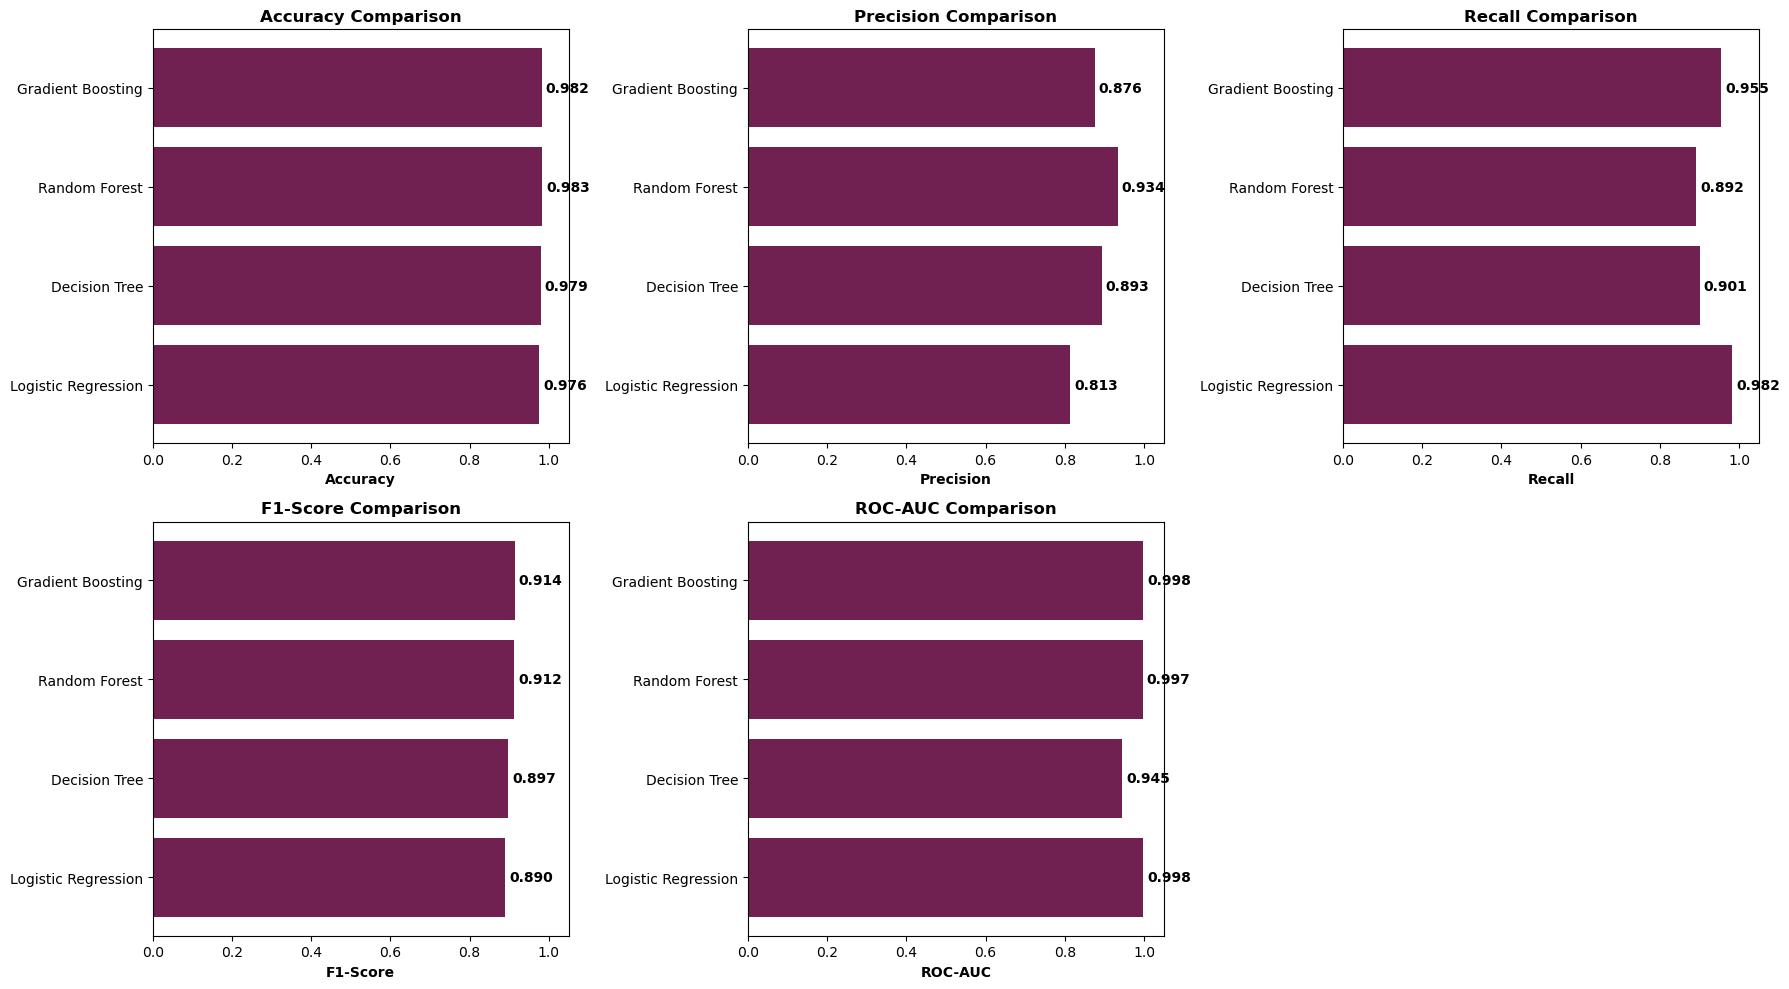

In [101]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()


metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

for idx, (metric, metric_name) in enumerate(zip(metrics, metrics_names)):
  
  values = [results[m][metric] for m in results]
  model_names = list(results.keys())

  
  axes[idx].barh(model_names, values, color='#702152')
  axes[idx].set_xlabel(metric_name, fontweight='bold')
  axes[idx].set_xlim(0, 1.05)  
  axes[idx].set_title(f'{metric_name} Comparison', fontweight='bold')

  
  for i, v in enumerate(values):
    axes[idx].text(v + 0.01, i, f'{v:.3f}', va='center', fontweight='semibold')


fig.delaxes(axes[5])

plt.tight_layout()
# plt.savefig('../reports/model_comparison_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [105]:
# Sort by Accuracy or F1-Score to get your actual best performing tree model
model_compare = model_compare.sort_values(
    'Accuracy', ascending=False
).reset_index(drop=True)

best_model_name = model_compare.iloc[0]['Model']
best_model_result = results[best_model_name]

print(f'Best Model : {best_model_name}')

Best Model : Random Forest


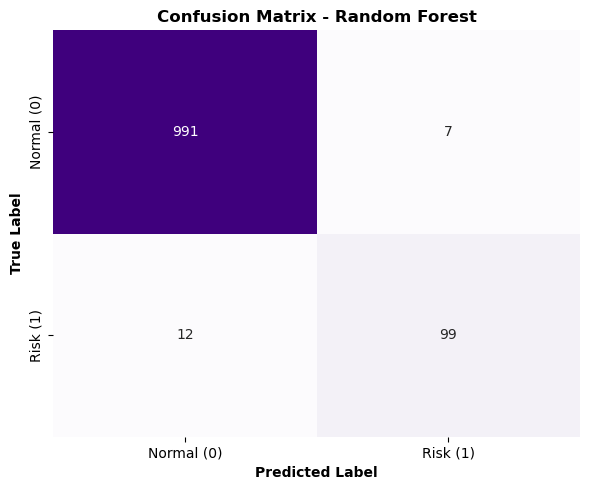

In [107]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get the predictions for your best model
y_pred = best_model_result['y_pred']

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',  # Matches your #702152 theme
    cbar=False,
    xticklabels=['Normal (0)', 'Risk (1)'],
    yticklabels=['Normal (0)', 'Risk (1)'],
)

plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.title(f'Confusion Matrix - {best_model_name}', fontweight='bold')

plt.tight_layout()
# plt.savefig('../reports/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

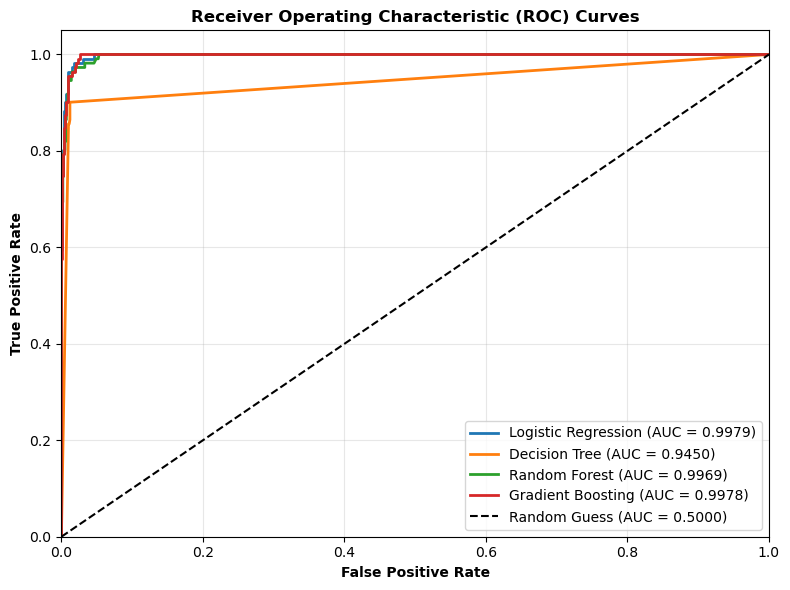

In [109]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Loop through each model in your results dictionary
for name, res in results.items():
  y_pred_proba = res['y_pred_proba']
  auc_score = res['roc_auc']

  # Compute False Positive Rate and True Positive Rate
  fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

  # Plot ROC curve with model name and its AUC score in the label
  plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})', linewidth=2)

# Plot the diagonal 50% random guess line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
plt.legend(loc='lower right', frameon=True)
plt.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig('../reports/roc_curves_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

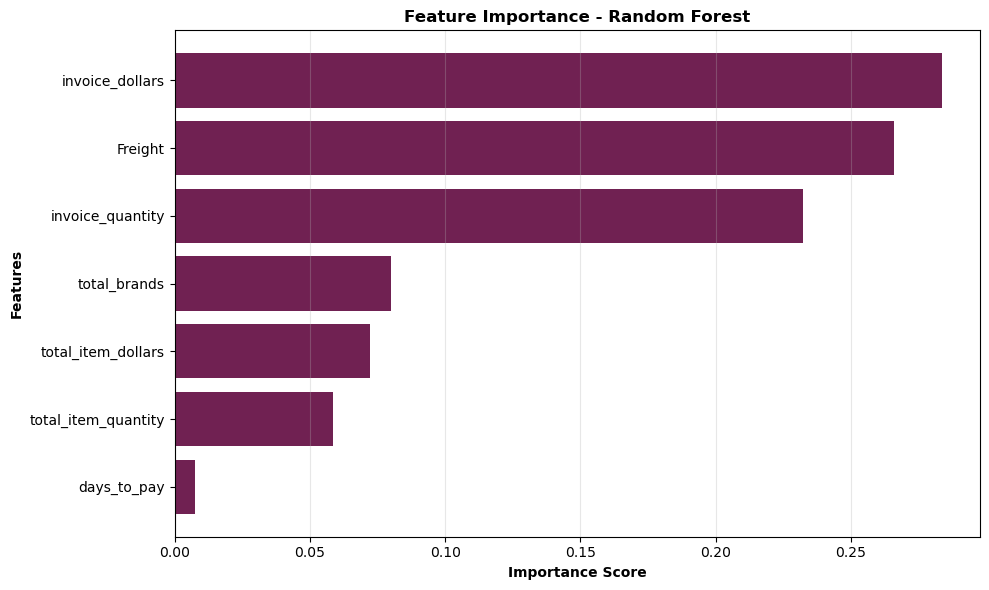

,Feature,Importance
1,invoice_dollars,0.283529
2,Freight,0.265976
0,invoice_quantity,0.232082
4,total_brands,0.080100
6,total_item_dollars,0.072232
5,total_item_quantity,0.058437
3,days_to_pay,0.007645


In [117]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Extract feature importances from your best model
importances = best_model_result['model'].feature_importances_
feature_names = X_train_scaled.columns

# 2. Create a dataframe and sort values for clean plotting
feature_importance_df = pd.DataFrame(
    {'Feature': feature_names, 'Importance': importances}
).sort_values(by='Importance', ascending=True)

# 3. Plot Feature Importances
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance_df['Feature'],
    feature_importance_df['Importance'],
    color='#702152',
)

plt.xlabel('Importance Score', fontweight='bold')
plt.ylabel('Features', fontweight='bold')
plt.title(f'Feature Importance - {best_model_name}', fontweight='bold')
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
# plt.savefig('../reports/feature_importances.png', dpi=300, bbox_inches='tight')
plt.show()

# Display the sorted dataframe table
feature_importance_df.sort_values(by='Importance', ascending=False)

In [119]:
import os
import joblib

model_path = '../models/invoice_risk_model.pkl'
scaler_path = '../models/risk_scaler.pkl'

joblib.dump(best_model_result['model'], model_path)
joblib.dump(preprocessor.scaler, scaler_path)

print(f'✅ Model Saved')
print(f'Model Path : {model_path}')
print(f'Scaler Path: {scaler_path}')


✅ Model Saved
Model Path : ../models/invoice_risk_model.pkl
